# 09 — Адаптація без міток на NIH: пріоритетна підмножина (EXPLORATORY)

Лише читає `reports/tables/adapt_nih_subset_*.csv` (3 енкодери × 2 бокс-запуски) і `adapt_bbbc_test_*.csv`.
Звіт: `reports/adapt_summary.md`. ДІ на NIH — bootstrap по пацієнтах (1000 ресемплів), на BBBC041 — по зображеннях.
`a_3s` на NIH немає (потрібні всі 3 бокс-запуски).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from malaria_ssl.detr.compare import plot_paired_diffs
from malaria_ssl.utils.config import resolve_path

T = resolve_path('reports/tables')
ENC = {'ssl_v2_b': 'b1', 'ssl_v2_b_seed43': 'b2', 'ref_dino': 'dino'}
RUN = {'a_coco_detr_binary': 'A42', 'a_coco_detr_binary_seed43': 'A43', 'a_coco_detr_binary_seed44': 'A44'}
METHODS = ['none', 'none_stainthr', 'adabn', 'none+em', 'adabn+em', 'none+bbse', 'adabn+bbse']

r = pd.read_csv(T / 'adapt_nih_subset_runs.csv')
d = pd.read_csv(T / 'adapt_nih_subset_diff.csv')
info = pd.read_csv(T / 'adapt_nih_subset_info.csv')
enc = pd.read_csv(T / 'adapt_nih_subset_encdiff.csv')
for df in (r, d, info):
    df['col'] = df['encoder'].map(ENC) + ' · ' + df['run'].map(RUN)
COLS = [f'{e} · {k}' for e in ENC.values() for k in ('A42', 'A43')]


def fmt(df):
    return df.assign(s=[f'{v:.3f} [{lo:.3f}, {hi:.3f}]' for v, lo, hi in zip(df['value'], df['ci_low'], df['ci_high'])])


def table(metric):
    t = fmt(r[(r['metric'] == metric) & r['method'].isin(METHODS)])
    return t.pivot(index='method', columns='col', values='s').reindex(METHODS)[COLS]

## NIH: AP50, recall, precision

`none` — поріг max F1 з чистого BBBC041 val; `+em` / `+bbse` — квантильний поріг за π̂.

In [2]:
table('AP50')

col,b1 · A42,b1 · A43,b2 · A42,b2 · A43,dino · A42,dino · A43
method,,,,,,
none,"0.567 [0.512, 0.618]","0.547 [0.491, 0.599]","0.586 [0.532, 0.633]","0.573 [0.518, 0.620]","0.434 [0.370, 0.495]","0.407 [0.344, 0.468]"
none_stainthr,"0.567 [0.512, 0.618]","0.547 [0.491, 0.599]","0.586 [0.532, 0.633]","0.573 [0.518, 0.620]","0.434 [0.370, 0.495]","0.407 [0.344, 0.468]"
adabn,"0.496 [0.429, 0.561]","0.515 [0.451, 0.579]","0.530 [0.467, 0.584]","0.534 [0.472, 0.587]","0.399 [0.337, 0.462]","0.376 [0.315, 0.436]"
none+em,"0.539 [0.485, 0.590]","0.512 [0.455, 0.563]","0.561 [0.508, 0.608]","0.536 [0.480, 0.584]","0.352 [0.294, 0.407]","0.304 [0.250, 0.358]"
adabn+em,"0.566 [0.508, 0.622]","0.561 [0.503, 0.616]","0.555 [0.496, 0.605]","0.542 [0.483, 0.592]","0.374 [0.315, 0.433]","0.330 [0.274, 0.389]"
none+bbse,"0.549 [0.495, 0.599]","0.523 [0.467, 0.574]","0.570 [0.517, 0.618]","0.549 [0.493, 0.596]","0.364 [0.305, 0.420]","0.326 [0.270, 0.382]"
adabn+bbse,"0.557 [0.498, 0.614]","0.556 [0.498, 0.613]","0.557 [0.498, 0.607]","0.546 [0.487, 0.597]","0.386 [0.325, 0.444]","0.346 [0.288, 0.406]"


In [3]:
table('recall')

col,b1 · A42,b1 · A43,b2 · A42,b2 · A43,dino · A42,dino · A43
method,,,,,,
none,"0.131 [0.106, 0.160]","0.110 [0.088, 0.136]","0.069 [0.052, 0.091]","0.076 [0.058, 0.098]","0.093 [0.071, 0.118]","0.120 [0.096, 0.148]"
none_stainthr,"0.098 [0.076, 0.124]","0.107 [0.086, 0.134]","0.079 [0.060, 0.103]","0.117 [0.094, 0.144]","0.143 [0.115, 0.174]","0.180 [0.147, 0.216]"
adabn,"0.535 [0.490, 0.583]","0.540 [0.496, 0.585]","0.319 [0.280, 0.359]","0.404 [0.362, 0.447]","0.229 [0.192, 0.268]","0.232 [0.195, 0.270]"
none+em,"0.010 [0.005, 0.015]","0.011 [0.006, 0.017]","0.013 [0.006, 0.023]","0.014 [0.007, 0.025]","0.050 [0.036, 0.066]","0.055 [0.040, 0.074]"
adabn+em,"0.594 [0.548, 0.641]","0.582 [0.537, 0.630]","0.300 [0.261, 0.342]","0.292 [0.252, 0.334]","0.165 [0.135, 0.199]","0.158 [0.127, 0.192]"
none+bbse,"0.188 [0.158, 0.222]","0.203 [0.172, 0.241]","0.273 [0.237, 0.312]","0.277 [0.240, 0.317]","0.088 [0.067, 0.112]","0.129 [0.101, 0.160]"
adabn+bbse,"0.736 [0.694, 0.777]","0.724 [0.680, 0.768]","0.553 [0.504, 0.599]","0.546 [0.498, 0.591]","0.295 [0.251, 0.339]","0.295 [0.252, 0.339]"


In [4]:
table('precision')

col,b1 · A42,b1 · A43,b2 · A42,b2 · A43,dino · A42,dino · A43
method,,,,,,
none,"0.908 [0.871, 0.936]","0.907 [0.867, 0.937]","0.921 [0.881, 0.951]","0.901 [0.853, 0.933]","0.819 [0.755, 0.867]","0.784 [0.719, 0.832]"
none_stainthr,"0.924 [0.886, 0.950]","0.908 [0.868, 0.937]","0.921 [0.884, 0.947]","0.893 [0.850, 0.922]","0.793 [0.732, 0.837]","0.736 [0.671, 0.785]"
adabn,"0.608 [0.540, 0.669]","0.617 [0.554, 0.674]","0.769 [0.714, 0.811]","0.711 [0.649, 0.759]","0.697 [0.632, 0.748]","0.657 [0.591, 0.711]"
none+em,"0.884 [0.768, 0.947]","0.895 [0.780, 0.955]","0.919 [0.824, 0.968]","0.918 [0.829, 0.967]","0.812 [0.742, 0.863]","0.754 [0.675, 0.813]"
adabn+em,"0.582 [0.515, 0.642]","0.583 [0.520, 0.639]","0.804 [0.757, 0.840]","0.792 [0.744, 0.830]","0.738 [0.674, 0.785]","0.688 [0.618, 0.742]"
none+bbse,"0.854 [0.810, 0.887]","0.809 [0.757, 0.848]","0.814 [0.773, 0.847]","0.768 [0.719, 0.806]","0.777 [0.707, 0.832]","0.701 [0.627, 0.756]"
adabn+bbse,"0.342 [0.284, 0.403]","0.347 [0.288, 0.407]","0.548 [0.474, 0.613]","0.544 [0.472, 0.606]","0.599 [0.533, 0.653]","0.530 [0.463, 0.589]"


## NIH: паразитемія на зображення (оцінена − справжня)

In [5]:
table('par_img_bias')

col,b1 · A42,b1 · A43,b2 · A42,b2 · A43,dino · A42,dino · A43
method,,,,,,
none,"-0.040 [-0.050, -0.031]","-0.042 [-0.052, -0.032]","-0.044 [-0.054, -0.034]","-0.043 [-0.054, -0.034]","-0.042 [-0.052, -0.032]","-0.040 [-0.050, -0.031]"
none_stainthr,"-0.042 [-0.052, -0.033]","-0.042 [-0.052, -0.032]","-0.043 [-0.053, -0.034]","-0.041 [-0.051, -0.032]","-0.039 [-0.048, -0.029]","-0.036 [-0.045, -0.027]"
adabn,"-0.004 [-0.010, 0.002]","-0.006 [-0.012, -0.001]","-0.026 [-0.034, -0.019]","-0.020 [-0.026, -0.013]","-0.032 [-0.040, -0.023]","-0.031 [-0.040, -0.023]"
none+em,"-0.047 [-0.057, -0.037]","-0.047 [-0.057, -0.037]","-0.047 [-0.057, -0.036]","-0.047 [-0.057, -0.036]","-0.044 [-0.055, -0.035]","-0.044 [-0.054, -0.034]"
adabn+em,"0.004 [-0.002, 0.010]","-0.000 [-0.006, 0.005]","-0.028 [-0.036, -0.021]","-0.029 [-0.037, -0.022]","-0.036 [-0.046, -0.028]","-0.037 [-0.046, -0.028]"
none+bbse,"-0.035 [-0.044, -0.027]","-0.035 [-0.044, -0.027]","-0.029 [-0.038, -0.022]","-0.030 [-0.038, -0.022]","-0.042 [-0.052, -0.032]","-0.039 [-0.049, -0.030]"
adabn+bbse,"0.055 [0.045, 0.066]","0.047 [0.038, 0.056]","0.004 [-0.002, 0.010]","0.001 [-0.005, 0.006]","-0.023 [-0.031, -0.016]","-0.022 [-0.030, -0.014]"


In [6]:
table('par_img_mae')

col,b1 · A42,b1 · A43,b2 · A42,b2 · A43,dino · A42,dino · A43
method,,,,,,
none,"0.040 [0.031, 0.050]","0.042 [0.033, 0.052]","0.044 [0.034, 0.054]","0.044 [0.034, 0.054]","0.043 [0.033, 0.052]","0.041 [0.032, 0.051]"
none_stainthr,"0.042 [0.033, 0.052]","0.042 [0.033, 0.052]","0.043 [0.034, 0.053]","0.042 [0.032, 0.051]","0.040 [0.031, 0.049]","0.038 [0.029, 0.047]"
adabn,"0.024 [0.020, 0.029]","0.023 [0.019, 0.028]","0.030 [0.023, 0.037]","0.027 [0.021, 0.033]","0.035 [0.027, 0.044]","0.035 [0.027, 0.044]"
none+em,"0.047 [0.037, 0.057]","0.047 [0.037, 0.057]","0.047 [0.036, 0.057]","0.047 [0.036, 0.057]","0.045 [0.035, 0.055]","0.044 [0.034, 0.055]"
adabn+em,"0.026 [0.022, 0.032]","0.024 [0.020, 0.029]","0.030 [0.023, 0.038]","0.032 [0.025, 0.040]","0.038 [0.029, 0.047]","0.039 [0.030, 0.048]"
none+bbse,"0.037 [0.029, 0.046]","0.036 [0.028, 0.045]","0.032 [0.025, 0.040]","0.032 [0.025, 0.040]","0.042 [0.033, 0.052]","0.040 [0.031, 0.050]"
adabn+bbse,"0.064 [0.054, 0.075]","0.057 [0.049, 0.065]","0.028 [0.023, 0.033]","0.027 [0.022, 0.032]","0.032 [0.025, 0.039]","0.033 [0.025, 0.040]"


## Оцінки частки infected π̂ проти справжньої

In [7]:
p = info[info['method'].isin(['none+em', 'none+bbse', 'adabn+em', 'adabn+bbse'])]
print('справжня частка infected клітин NIH:', p['true_cell_pi'].unique())
p.pivot(index='method', columns='col', values='pi_hat')[COLS].round(4)

справжня частка infected клітин NIH: [0.0405]


col,b1 · A42,b1 · A43,b2 · A42,b2 · A43,dino · A42,dino · A43
method,,,,,,
adabn+bbse,0.0854,0.0881,0.0387,0.0383,0.0177,0.0210
adabn+em,0.0400,0.0403,0.0142,0.0141,0.0081,0.0086
none+bbse,0.0080,0.0093,0.0123,0.0132,0.0040,0.0066
none+em,0.0004,0.0005,0.0005,0.0006,0.0021,0.0026


In [8]:
bi = pd.read_csv(T / 'adapt_bbbc_test_info.csv')
bi = bi[bi['encoder'].isin(ENC) & bi['method'].isin(['none+em', 'none+bbse', 'adabn+em', 'adabn+bbse'])]
print('справжня частка infected клітин BBBC041 test:', bi['true_cell_pi'].unique())
bi.assign(col=bi['encoder'].map(ENC) + ' · ' + bi['run'].map(RUN)).pivot(
    index='method', columns='col', values='pi_hat').round(4)

справжня частка infected клітин BBBC041 test: [0.0512]


col,b1 · A42,b1 · A43,b1 · A44,b2 · A42,b2 · A43,b2 · A44,dino · A42,dino · A43,dino · A44
method,,,,,,,,,
adabn+bbse,0.0751,0.0779,0.0723,0.0637,0.0663,0.0630,0.0477,0.0507,0.0457
adabn+em,0.0593,0.0610,0.0577,0.0508,0.0523,0.0488,0.0393,0.0419,0.0389
none+bbse,0.0414,0.0442,0.0411,0.0393,0.0399,0.0368,0.0463,0.0507,0.0450
none+em,0.0278,0.0293,0.0260,0.0241,0.0254,0.0229,0.0389,0.0424,0.0382


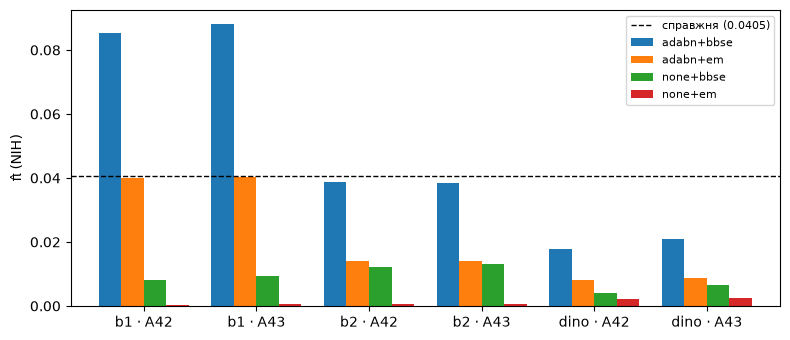

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
q = p.pivot(index='col', columns='method', values='pi_hat').reindex(COLS)
q.plot.bar(ax=ax, width=0.8)
ax.axhline(p['true_cell_pi'].iloc[0], color='black', ls='--', lw=1, label='справжня (0.0405)')
ax.set_ylabel('π̂ (NIH)')
ax.set_xlabel('')
ax.legend(fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()

## Парні різниці `adabn+em − none` (NIH)

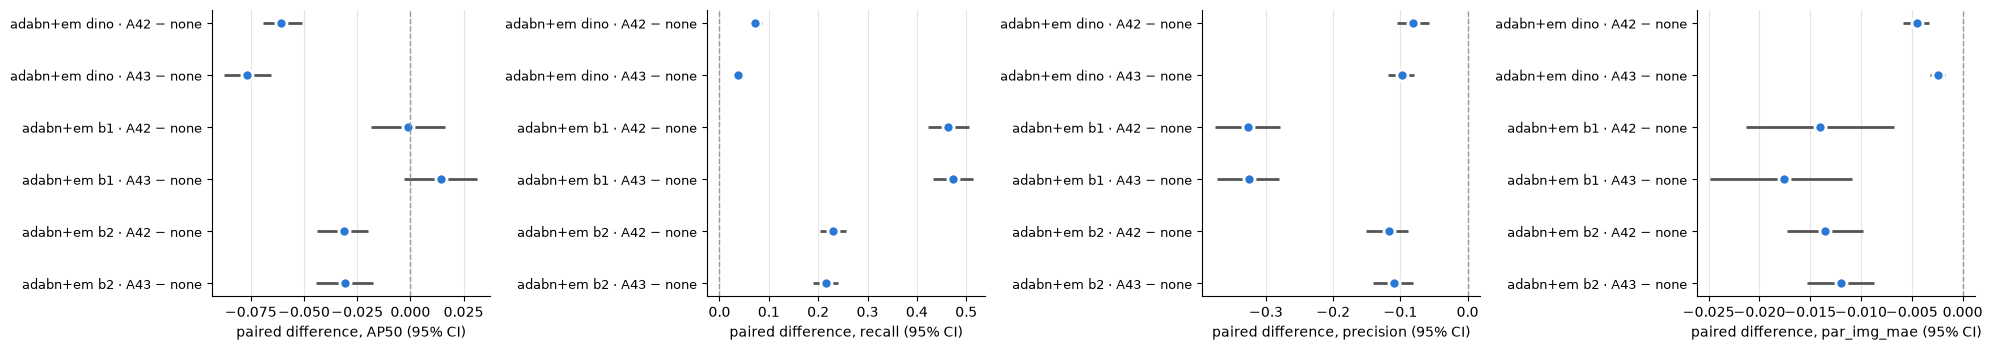

In [10]:
x = d[d['pair'] == 'adabn+em - none'].copy()
x['a'], x['b'] = 'adabn+em ' + x['col'], 'none'
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
for ax, m in zip(axes, ['AP50', 'recall', 'precision', 'par_img_mae']):
    plot_paired_diffs(x, m, ax)
plt.tight_layout()

## Парні різниці `ssl_v2_b − ref_dino` (NIH, `none` і `adabn+em`)

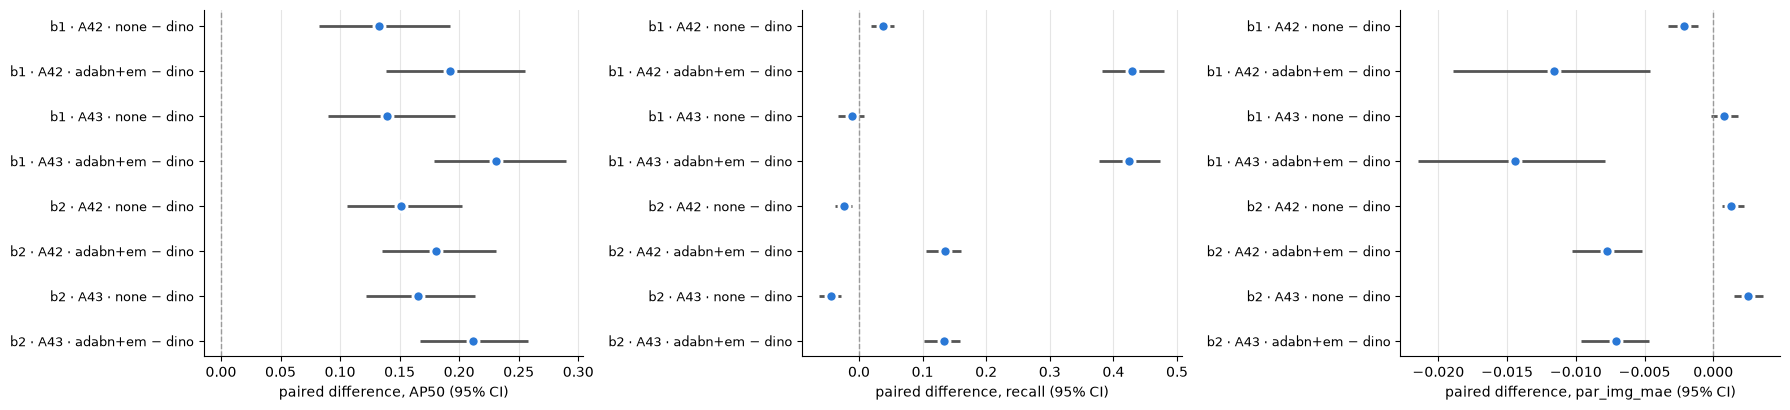

In [11]:
e = enc[enc['method'].isin(['none', 'adabn+em'])].copy()
e['a'] = e['pair'].str.split(' - ').str[0].map(ENC) + ' · ' + e['run'].map(RUN) + ' · ' + e['method']
e['b'] = 'dino'
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, m in zip(axes, ['AP50', 'recall', 'par_img_mae']):
    plot_paired_diffs(e, m, ax)
plt.tight_layout()

## Повторюваність ефекту `adabn+em − none`

Кількість пар (енкодер × бокс-запуск) з ДІ без 0 за знаком; NIH — 6 пар, BBBC041 test — 18 пар (без `a_3s`).

In [12]:
def count(df):
    df = df[df['pair'] == 'adabn+em - none']
    return pd.DataFrame({'n': df.groupby('metric').size(),
                         'up*': df[df['excludes_0'] & (df['diff'] > 0)].groupby('metric').size(),
                         'down*': df[df['excludes_0'] & (df['diff'] < 0)].groupby('metric').size()}).fillna(0).astype(int)


bd = pd.read_csv(T / 'adapt_bbbc_test_diff.csv')
keep = ['AP50', 'recall', 'precision', 'f1', 'par_img_bias', 'par_img_mae', 'screen_auroc', 'crop_auprc']
pd.concat({'NIH': count(d), 'BBBC041 test': count(bd[bd['run'] != 'a_3s'])}, axis=1).reindex(keep)

NIH           BBBC041 test            
               n up* down*            n   up* down*
metric                                             
AP50           6   0     4         18.0   3.0  11.0
recall         6   6     0         18.0  18.0   0.0
precision      6   0     6         18.0   0.0  15.0
f1             6   6     0         18.0  16.0   0.0
par_img_bias   6   6     0         18.0  18.0   0.0
par_img_mae    6   0     6         18.0   0.0   6.0
screen_auroc   6   3     0         18.0   4.0   0.0
crop_auprc     6   2     4         18.0   3.0   4.0

## NIH: `none` за біном справжньої паразитемії зображення

In [13]:
b = pd.read_csv(T / 'adapt_nih_subset_bins.csv')
b = b[(b['method'] == 'none') & b['metric'].isin(['recall', 'par_img_bias'])]
b = b.assign(col=b['encoder'].map(ENC) + ' · ' + b['run'].map(RUN))
b.pivot_table(index=['metric', 'bin'], columns='col', values='value', aggfunc='first', sort=False)[COLS].round(3)

col                     b1 · A42  b1 · A43  b2 · A42  b2 · A43  dino · A42  \
metric       bin                                                             
recall       (0, 1%)       0.080     0.093     0.074     0.068       0.136   
             [1%, 5%)      0.135     0.113     0.087     0.094       0.112   
             [5%, 20%)     0.139     0.117     0.075     0.081       0.099   
             >= 20%        0.122     0.098     0.052     0.061       0.072   
par_img_bias 0             0.000     0.000     0.000     0.000       0.001   
             (0, 1%)      -0.005    -0.005    -0.005    -0.005      -0.004   
             [1%, 5%)     -0.021    -0.022    -0.023    -0.023      -0.021   
             [5%, 20%)    -0.091    -0.094    -0.098    -0.098      -0.095   
             >= 20%       -0.242    -0.253    -0.267    -0.265      -0.260   

col                     dino · A43  
metric       bin                    
recall       (0, 1%)         0.185  
             [1%, 5%)        0.138  
             [5%, 20%)       0.124  
             >= 20%          0.103  
par_img_bias 0               0.001  
             (0, 1%)        -0.003  
             [1%, 5%)       -0.020  
             [5%, 20%)      -0.093  
             >= 20%         -0.250